# Diabetes Classification with Nonlinear SVM

Python experiments on diabetes classification: **polynomial and RBF Support Vector Machines**, compared with Random Forest, Logistic Regression, KNN and Decision Tree.

**Workflow:** load and explore the data → standardize → stratified split → SMOTE on the training set → `SelectKBest` feature selection → SVMs → comparison models → hyper-parameter tuning (Decision Tree, KNN).

> This is a learning/experimentation notebook. The figures below are the results *reported by this notebook* in its original run; they are not independently verified benchmarks, and the model is not a clinically validated prediction system.

The notebook expects a local CSV named `diabetes - Copy.csv` (768 rows; 8 features + `Outcome`), which is not included in the repository. See the README, *Dataset*.

In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn import svm
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import RFE
from sklearn.feature_selection import SelectFromModel
from sklearn.svm import SVC
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
np.random.seed(16)

In [2]:
import warnings
warnings.filterwarnings(action='ignore')

## 1. Load and explore the data
768 rows × 9 columns, no null values; `Outcome` is 0 for 500 rows and 1 for 268 rows. Note that several clinical columns (e.g. Glucose, BloodPressure, SkinThickness, Insulin, BMI) contain zeros, which the notebook keeps as they are.

In [3]:
df = pd.read_csv('diabetes - Copy.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [6]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [7]:
df.shape

(768, 9)

In [8]:
df['Outcome'].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

In [9]:
df.groupby('Outcome').mean()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,3.298000,109.980000,68.184000,19.664000,68.792000,30.304200,0.429734,31.190000
1,4.865672,141.257463,70.824627,22.164179,100.335821,35.142537,0.550500,37.067164


In [10]:
Input_data = df.drop(columns='Outcome', axis=1)
Labels = df['Outcome']

In [11]:
Input_data

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63
764,2,122,70,27,0,36.8,0.340,27
765,5,121,72,23,112,26.2,0.245,30
766,1,126,60,0,0,30.1,0.349,47


In [12]:
Labels

0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64

## 2. Visual exploration
Feature histograms with KDE, plus the class distribution as a count plot and a pie chart.

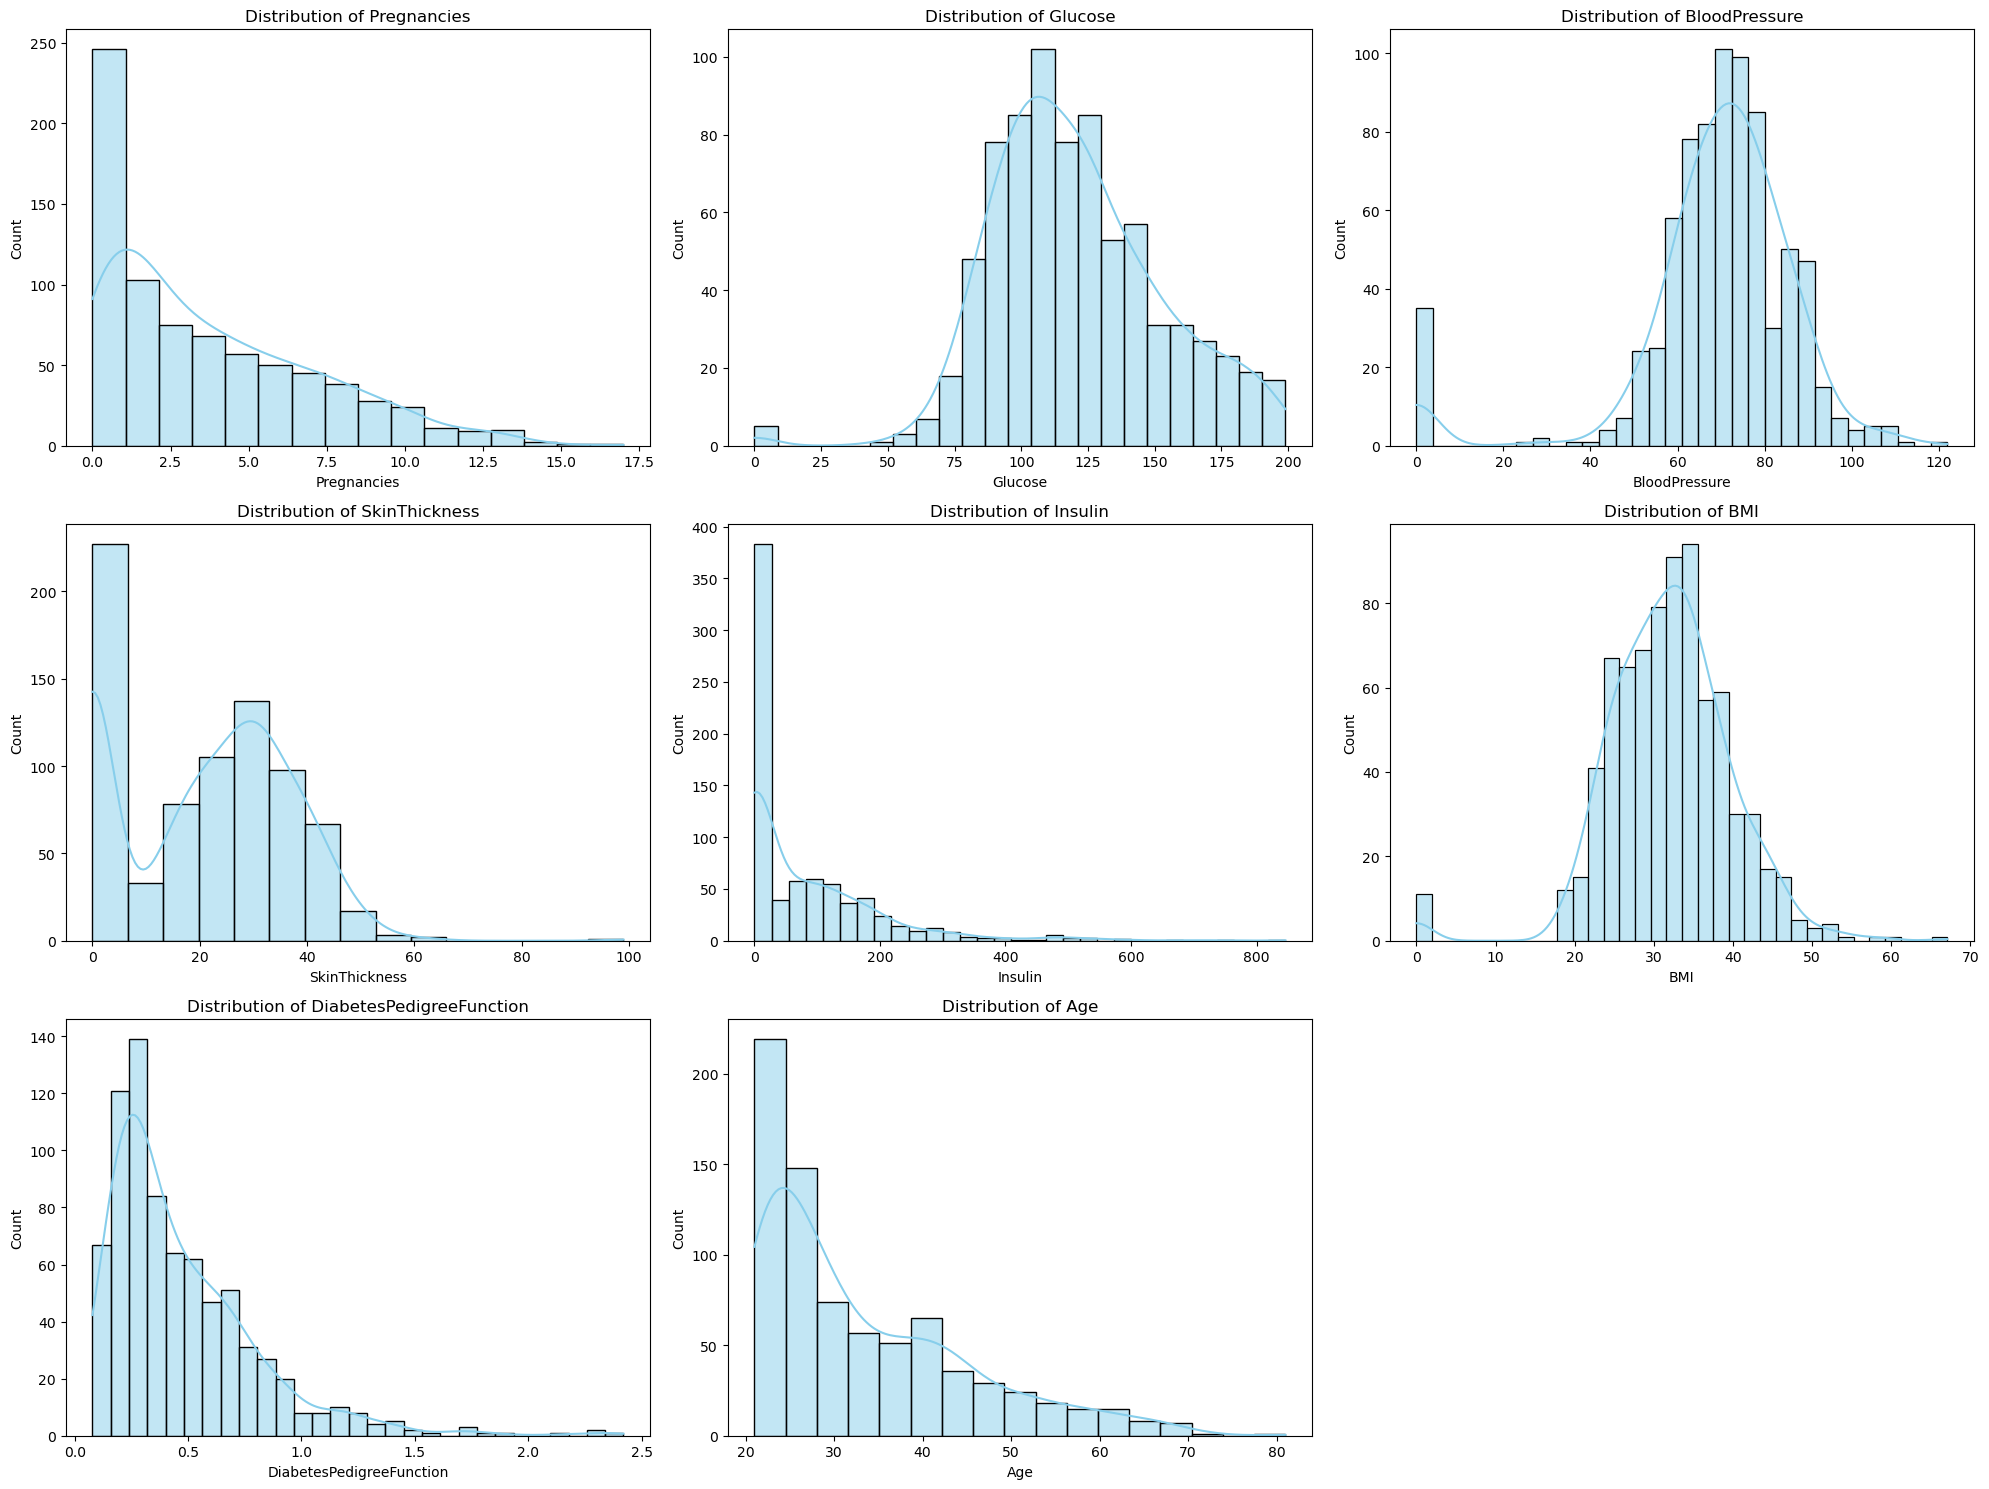

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# إعداد شكل الرسم
plt.figure(figsize=(20, 15))

# رسم جميع الأعمدة
for idx, column in enumerate(Input_data.columns, 1):
    plt.subplot(3, 3, idx) # توزيع الرسومات في شبكة 3x3
    sns.histplot(Input_data[column], kde=True, color='skyblue')
    plt.title(f'Distribution of {column}', fontsize=12)

plt.tight_layout()
plt.show()


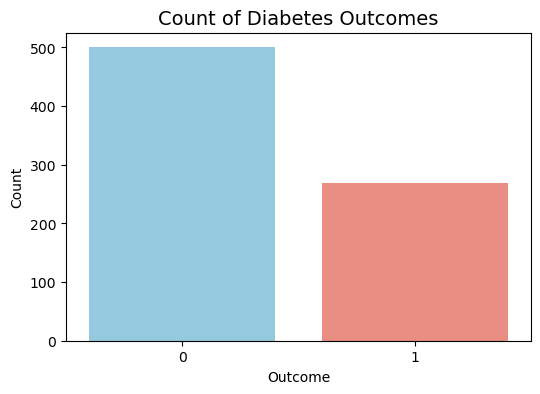

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Outcome', palette=['skyblue', 'salmon'])
plt.title('Count of Diabetes Outcomes', fontsize=14)
plt.xlabel('Outcome')
plt.ylabel('Count')
plt.show()


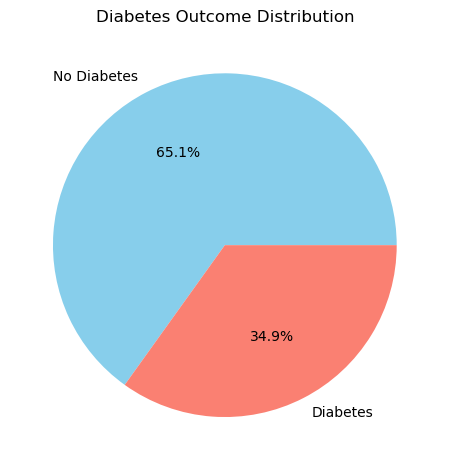

In [15]:
df['Outcome'].value_counts().plot(kind='pie', autopct='%1.1f%%', labels=['No Diabetes', 'Diabetes'], colors=['skyblue', 'salmon'])
plt.title('Diabetes Outcome Distribution')
plt.ylabel('')
plt.tight_layout()
plt.show()

## 3. Standardization
`StandardScaler` is fitted on the full feature matrix and applied to all rows before the train/test split.

In [16]:
#initialization of StandardScaler by removing the mean and scaling to unit variance
scaler = StandardScaler()

In [17]:
#fitting the data by coputing the mean and std based on scaling
scaler.fit(Input_data)

StandardScaler()

In [18]:
#standardized the data
standardized_data = scaler.transform(Input_data)

In [19]:
print(standardized_data)

[[ 0.63994726  0.84832379  0.14964075 ...  0.20401277  0.46849198
   1.4259954 ]
 [-0.84488505 -1.12339636 -0.16054575 ... -0.68442195 -0.36506078
  -0.19067191]
 [ 1.23388019  1.94372388 -0.26394125 ... -1.10325546  0.60439732
  -0.10558415]
 ...
 [ 0.3429808   0.00330087  0.14964075 ... -0.73518964 -0.68519336
  -0.27575966]
 [-0.84488505  0.1597866  -0.47073225 ... -0.24020459 -0.37110101
   1.17073215]
 [-0.84488505 -0.8730192   0.04624525 ... -0.20212881 -0.47378505
  -0.87137393]]


In [20]:
Input_data = standardized_data
Labels = df['Outcome']

In [21]:
Input_data

array([[ 0.63994726,  0.84832379,  0.14964075, ...,  0.20401277,
         0.46849198,  1.4259954 ],
       [-0.84488505, -1.12339636, -0.16054575, ..., -0.68442195,
        -0.36506078, -0.19067191],
       [ 1.23388019,  1.94372388, -0.26394125, ..., -1.10325546,
         0.60439732, -0.10558415],
       ...,
       [ 0.3429808 ,  0.00330087,  0.14964075, ..., -0.73518964,
        -0.68519336, -0.27575966],
       [-0.84488505,  0.1597866 , -0.47073225, ..., -0.24020459,
        -0.37110101,  1.17073215],
       [-0.84488505, -0.8730192 ,  0.04624525, ..., -0.20212881,
        -0.47378505, -0.87137393]])

In [22]:
Labels

0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64

## 4. Train/test split and SMOTE
Stratified 80/20 split (`random_state=16`): 614 training / 154 test rows. SMOTE is applied to the training set only, balancing it to 400 / 400 (800 rows).

In [23]:
pip install imbalanced-learn


In [24]:
X_train, X_test, Y_train, Y_test = train_test_split(Input_data, Labels, test_size=0.2, stratify=Labels, random_state=16)

In [25]:
smote = SMOTE(random_state=2)
X_train_res, Y_train_res = smote.fit_resample(X_train, Y_train)

In [26]:
print(f"Original train set shape: {X_train.shape}, {Y_train.value_counts()}")
print(f"Resampled train set shape: {X_train_res.shape}, {pd.Series(Y_train_res).value_counts()}")

Original train set shape: (614, 8), Outcome
0    400
1    214
Name: count, dtype: int64
Resampled train set shape: (800, 8), Outcome
1    400
0    400
Name: count, dtype: int64


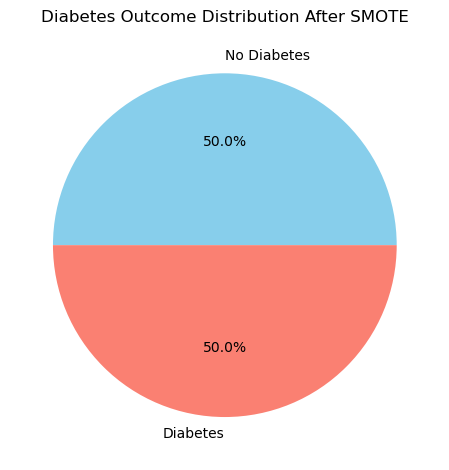

In [27]:
pd.Series(Y_train_res).value_counts().plot(kind='pie', autopct='%1.1f%%', labels=['No Diabetes', 'Diabetes'], colors=['skyblue', 'salmon'])
plt.title('Diabetes Outcome Distribution After SMOTE')
plt.ylabel('')  
plt.tight_layout()
plt.show()

In [28]:
Input_data.shape, X_train.shape, X_test.shape

((768, 8), (614, 8), (154, 8))

## 5. Feature selection and polynomial-kernel SVM
`SelectKBest(mutual_info_classif, k=6)` is fitted on the resampled training data and keeps feature indices 0, 1, 2, 3, 5, 7 (Pregnancies, Glucose, BloodPressure, SkinThickness, BMI, Age). An `SVC(kernel='poly')` is trained on them.

Saved result: test accuracy 0.7792 (class 1 recall 0.56).

In [29]:
selector = SelectKBest(score_func=mutual_info_classif, k=6)
X_train_selected = selector.fit_transform(X_train_res, Y_train_res)

In [30]:
selected_features = selector.get_support(indices=True)
print(selected_features)

[0 1 2 3 5 7]


In [31]:
classifier_poly =svm.SVC(C=1.0, kernel='poly',random_state=16)
classifier_poly.fit(X_train_selected, Y_train_res)

SVC(kernel='poly', random_state=16)

In [32]:
X_test_selected = selector.transform(X_test)

In [33]:
X_train_prediction_poly = classifier_poly.predict(X_train_selected)
training_data_accuracy_poly = accuracy_score(X_train_prediction_poly, Y_train_res)
print('Accuracy score of the training data : ', training_data_accuracy_poly)

Accuracy score of the training data :  0.75625


In [34]:
y_pred_poly = classifier_poly.predict(X_test_selected)
print("Accuracy on test set:", accuracy_score(Y_test, y_pred_poly))
print("\nClassification Report:")
print(classification_report(Y_test, y_pred_poly))

Accuracy on test set: 0.7792207792207793

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.90      0.84       100
           1       0.75      0.56      0.64        54

    accuracy                           0.78       154
   macro avg       0.77      0.73      0.74       154
weighted avg       0.78      0.78      0.77       154



## 6. RBF-kernel SVM
Same feature selection, `SVC(kernel='rbf')`.

Saved result: test accuracy 0.8117 (class 1 precision 0.69, recall 0.83).

In [35]:
selector = SelectKBest(score_func=mutual_info_classif, k=6)
X_train_selected = selector.fit_transform(X_train_res, Y_train_res)

In [36]:
classifier_rbf =svm.SVC(C=1.0, kernel='rbf',random_state=16)
classifier_rbf.fit(X_train_selected, Y_train_res)

SVC(random_state=16)

In [37]:
X_test_selected = selector.transform(X_test)

In [38]:
X_train_prediction_rbf = classifier_rbf.predict(X_train_selected)
training_data_accuracy_rbf = accuracy_score(X_train_prediction_rbf, Y_train_res)

# طباعة النتيجة
print('Accuracy score of the training data : ', training_data_accuracy_rbf)

Accuracy score of the training data :  0.805


In [39]:
y_pred_rbf = classifier_rbf.predict(X_test_selected)
print("Accuracy on test set:", accuracy_score(Y_test, y_pred_rbf))
print("\nClassification Report:")
print(classification_report(Y_test, y_pred_rbf))

Accuracy on test set: 0.8116883116883117

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.80      0.85       100
           1       0.69      0.83      0.76        54

    accuracy                           0.81       154
   macro avg       0.80      0.82      0.80       154
weighted avg       0.83      0.81      0.81       154



## 7. SVM kernel comparison
Bar chart of the two SVMs' training vs. test accuracy. The values in this chart were entered manually from the printed results above.

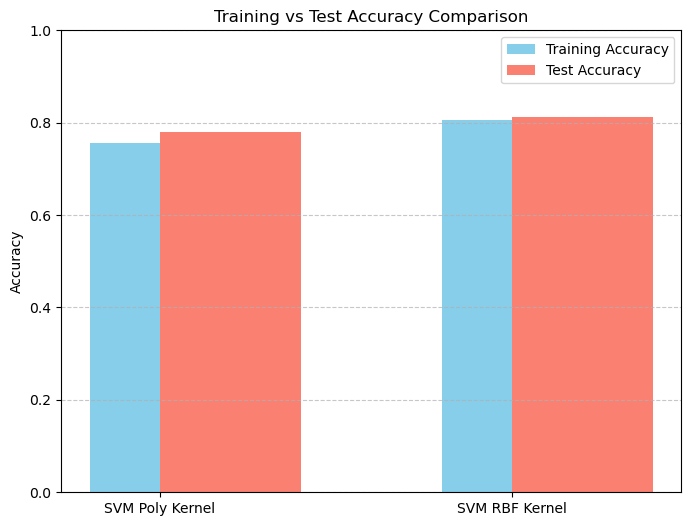

In [61]:
import matplotlib.pyplot as plt

# بيانات الدقة
models = ['SVM Poly Kernel', 'SVM RBF Kernel']
train_accuracy = [0.75625, 0.805]
test_accuracy = [0.7792, 0.8117]

x = range(len(models))

plt.figure(figsize=(8, 6))
plt.bar(x, train_accuracy, width=0.4, label='Training Accuracy', align='center', color='skyblue')
plt.bar(x, test_accuracy, width=0.4, label='Test Accuracy', align='edge', color='salmon')
plt.xticks(x, models)
plt.ylabel('Accuracy')
plt.title('Training vs Test Accuracy Comparison')
plt.legend()
plt.ylim(0, 1)  # تحديد الحدود من 0 إلى 1
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


## 8. Single-record prediction demo
Runs one hand-entered example through the scaler, feature selector and each SVM (poly, then RBF). This is a usage demonstration, not an evaluation.

In [40]:
#Making a predictive system for diabetes (poly)
input_data = (1,85,66,29,0,26.6,0.351,31)

#changing the input data to numpy array
input_data_as_numpy_array = np.asarray(input_data).reshape(1, -1)

#standardize the input data
std_data = scaler.transform(input_data_as_numpy_array)
print(f'Standardized data is :\n {std_data}')
print("")
#reshape the array as we are predicting for one instance
input_data_selected_features = selector.transform(std_data)

prediction = classifier_poly.predict(input_data_selected_features)
print(f"System prediction is class : {prediction}")

if (prediction[0]==0):
  print('The person is not diabetic')
else:
    print('The person is diabetic')

Standardized data is :
 [[-0.84488505 -1.12339636 -0.16054575  0.53090156 -0.69289057 -0.68442195
  -0.36506078 -0.19067191]]

System prediction is class : [0]
The person is not diabetic


In [41]:
#Making a predictive system for diabetes (rbf)
input_data = (1,85,66,29,0,26.6,0.351,31)

#changing the input data to numpy array
input_data_as_numpy_array = np.asarray(input_data).reshape(1, -1)


#standardize the input data
std_data = scaler.transform(input_data_as_numpy_array)
print(f'Standardized data is :\n {std_data}')
print("")
#reshape the array as we are predicting for one instance
input_data_selected_features = selector.transform(std_data)

prediction = classifier_rbf.predict(input_data_selected_features)
print(f"System prediction is class : {prediction}")

if (prediction[0]==0):
  print('The person is not diabetic')
else:
    print('The person is diabetic')

Standardized data is :
 [[-0.84488505 -1.12339636 -0.16054575  0.53090156 -0.69289057 -0.68442195
  -0.36506078 -0.19067191]]

System prediction is class : [0]
The person is not diabetic


## 9. Comparison models
Re-scales the selected features and trains Random Forest, Logistic Regression, KNN and Decision Tree with default settings.

Saved test accuracies: Random Forest 0.82, Logistic Regression 0.79, KNN 0.75, Decision Tree 0.68. The bar chart that follows uses values typed in from the class-0 rows of these reports.

In [42]:
scaler_selected = StandardScaler()
X_train_scaled = scaler_selected.fit_transform(X_train_selected)  # تدريب على X_train
X_test_scaled = scaler_selected.transform(X_test_selected)  # تطبيق على X_test

In [43]:
classifier_randomforest = RandomForestClassifier()
classifier_randomforest.fit(X_train_scaled, Y_train_res)
X_test_prediction_randomforest = classifier_randomforest.predict(X_test_scaled)

In [44]:
classifier_logisticregression = LogisticRegression()
classifier_logisticregression.fit(X_train_scaled, Y_train_res)
X_test_prediction_logisticregression = classifier_logisticregression.predict(X_test_scaled)

In [45]:
classifier_knn = KNeighborsClassifier()
classifier_knn.fit(X_train_scaled,  Y_train_res)
X_test_prediction_knn = classifier_knn.predict(X_test_scaled)

In [46]:
classifier_decisiontree = DecisionTreeClassifier()
classifier_decisiontree.fit(X_train_scaled,  Y_train_res)
X_test_prediction_decisiontree = classifier_decisiontree.predict(X_test_scaled)

In [47]:
from sklearn.metrics import classification_report

print("Classification Report for Random Forest:\n", classification_report(Y_test, X_test_prediction_randomforest))
print("Classification Report for Logistic Regression:\n", classification_report(Y_test, X_test_prediction_logisticregression))
print("Classification Report for K-Nearest Neighbors:\n", classification_report(Y_test, X_test_prediction_knn))
print("Classification Report for Decision Tree:\n", classification_report(Y_test, X_test_prediction_decisiontree))


Classification Report for Random Forest:
               precision    recall  f1-score   support

           0       0.87      0.85      0.86       100
           1       0.73      0.76      0.75        54

    accuracy                           0.82       154
   macro avg       0.80      0.80      0.80       154
weighted avg       0.82      0.82      0.82       154

Classification Report for Logistic Regression:
               precision    recall  f1-score   support

           0       0.88      0.78      0.83       100
           1       0.66      0.80      0.72        54

    accuracy                           0.79       154
   macro avg       0.77      0.79      0.77       154
weighted avg       0.80      0.79      0.79       154

Classification Report for K-Nearest Neighbors:
               precision    recall  f1-score   support

           0       0.86      0.74      0.80       100
           1       0.62      0.78      0.69        54

    accuracy                           0.75 

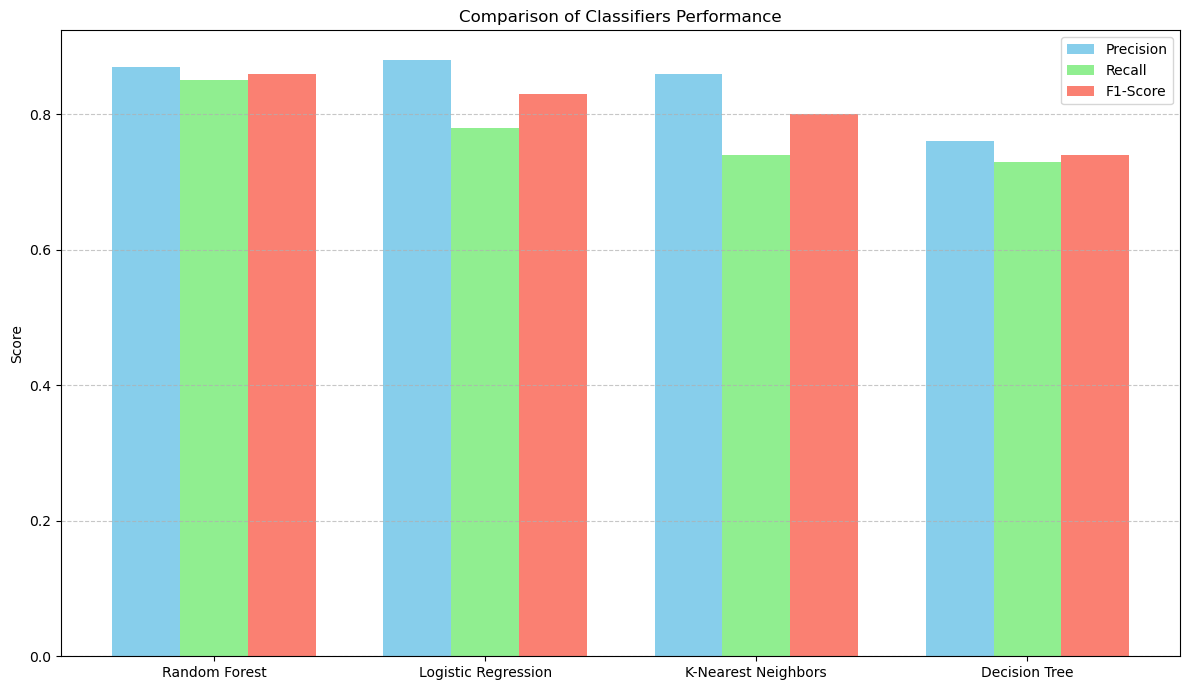

In [63]:
import matplotlib.pyplot as plt
import numpy as np

# المصنفات
models = ['Random Forest', 'Logistic Regression', 'K-Nearest Neighbors', 'Decision Tree']

# المقاييس (من التقارير اللي طلعتيها فوق)
precision = [0.87, 0.88, 0.86, 0.76]  # للـ Class 0 فقط مثلاً، أو تقدري تاخذي المتوسط لو تبغين
recall = [0.85, 0.78, 0.74, 0.73]
f1_score = [0.86, 0.83, 0.80, 0.74]

x = np.arange(len(models))  # أماكن العواميد
width = 0.25  # عرض العمود

fig, ax = plt.subplots(figsize=(12, 7))

# رسم العواميد
ax.bar(x - width, precision, width, label='Precision', color='skyblue')
ax.bar(x, recall, width, label='Recall', color='lightgreen')
ax.bar(x + width, f1_score, width, label='F1-Score', color='salmon')

# إضافة تفاصيل الرسم
ax.set_ylabel('Score')
ax.set_title('Comparison of Classifiers Performance')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


## 10. Additional polynomial-SVM experiment (k = 7)
Repeats feature selection with `k=7` and re-splits the resampled training data. Because this section reuses and re-assigns several arrays, its printed accuracy (0.7662) is not directly comparable with the earlier SVM results.

In [48]:
selector = SelectKBest(score_func=mutual_info_classif, k=7)
X_train_selected = selector.fit_transform(X_train_res, Y_train_res)
X_test_selected = selector.transform(X_test)

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X_train_selected, Y_train_res, test_size=0.2, random_state=42)

In [50]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [51]:
classifier_poly = svm.SVC(C=1.0, kernel='poly', random_state=16)
classifier_poly.fit(X_train, y_train)

SVC(kernel='poly', random_state=16)

In [52]:
X_train_prediction_poly = classifier_poly.predict(X_train_selected)
training_data_accuracy_poly = accuracy_score(X_train_prediction_poly, Y_train_res)
print('Accuracy score of the training data : ', training_data_accuracy_poly)


Accuracy score of the training data :  0.785


In [53]:
y_pred_poly = classifier_poly.predict(X_test_selected)
print("Accuracy on test set:", accuracy_score(Y_test, y_pred_poly))
print("\nClassification Report:")
print(classification_report(Y_test, y_pred_poly))

Accuracy on test set: 0.7662337662337663

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.83      0.82       100
           1       0.67      0.65      0.66        54

    accuracy                           0.77       154
   macro avg       0.74      0.74      0.74       154
weighted avg       0.76      0.77      0.77       154



## 11. Hyper-parameter tuning
`GridSearchCV` (5-fold, accuracy) for Decision Tree (best: `max_depth=20`, `min_samples_leaf=2`, `min_samples_split=10`; test accuracy 0.7468) and KNN (test accuracy 0.7208).

In [54]:
from sklearn.model_selection import GridSearchCV
param_grid_dt = {
    'max_depth': [None, 10, 20, 30], 
    'min_samples_split': [2, 5, 10],  
    'min_samples_leaf': [1, 2, 4],   
}

In [55]:
grid_search_dt = GridSearchCV(DecisionTreeClassifier(), param_grid_dt, cv=5, scoring='accuracy')

In [56]:
grid_search_dt.fit(X_train_scaled, Y_train_res)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'max_depth': [None, 10, 20, 30],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10]},
             scoring='accuracy')

In [57]:
best_dt = grid_search_dt.best_estimator_
best_dt.fit(X_train_scaled, Y_train_res)

DecisionTreeClassifier(max_depth=20, min_samples_leaf=2, min_samples_split=10)

In [58]:
X_test_prediction_decisiontree = best_dt.predict(X_test_scaled)

In [59]:
accuracy = accuracy_score(Y_test, X_test_prediction_decisiontree)
print("Best Decision Tree Model Accuracy on test set:", accuracy)

Best Decision Tree Model Accuracy on test set: 0.7467532467532467


In [60]:
param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

grid_search_knn = GridSearchCV(KNeighborsClassifier(), param_grid_knn, cv=5, scoring='accuracy')
grid_search_knn.fit(X_train_scaled, Y_train_res)

best_knn = grid_search_knn.best_estimator_

best_knn.fit(X_train_scaled, Y_train_res)
X_test_prediction_knn = best_knn.predict(X_test_scaled)
print("Best KNN Model Accuracy on test set:", accuracy_score(Y_test, X_test_prediction_knn))

Best KNN Model Accuracy on test set: 0.7207792207792207


## 12. Before/after tuning summary
Bar chart of baseline vs. tuned accuracy (values entered manually).

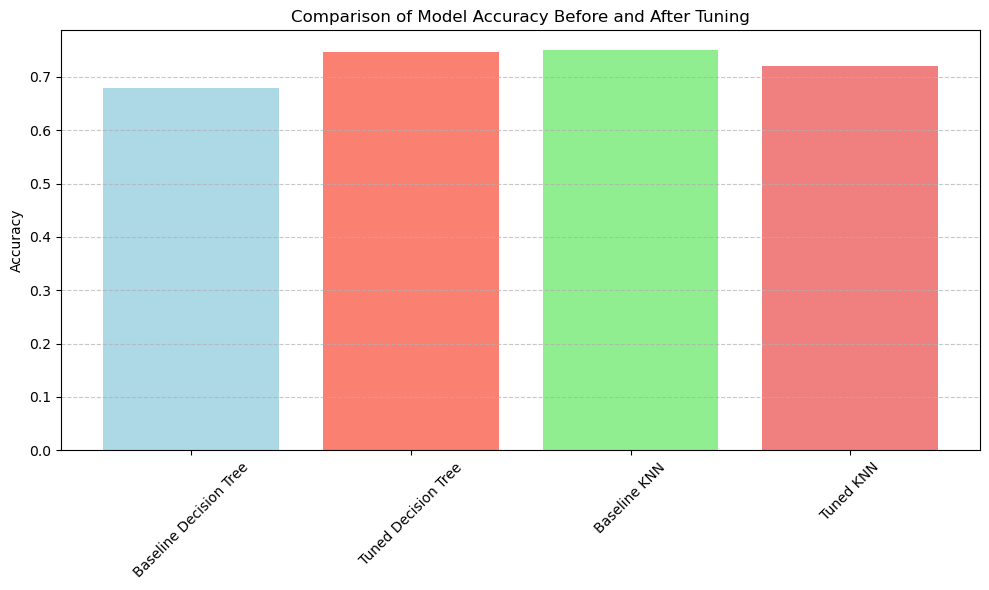

In [73]:
import matplotlib.pyplot as plt
import numpy as np

models = ['Baseline Decision Tree', 'Tuned Decision Tree', 'Baseline KNN', 'Tuned KNN']
accuracies = [0.68, 0.7467, 0.75, 0.7207]

x = np.arange(len(models))
plt.figure(figsize=(10, 6))
plt.bar(x, accuracies, color=['lightblue', 'salmon', 'lightgreen', 'lightcoral'])  # الألوان المتناسقة مع السكاي بلو والسالمون
plt.xticks(x, models, rotation=45)
plt.ylabel('Accuracy')
plt.title('Comparison of Model Accuracy Before and After Tuning')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

